In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, utils
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# 1. Load & Preprocess Data
# ----------------------------
df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/merged_aqi_corrected_cleaned.csv")
df['Date'] = pd.to_datetime(df['Date']) # Corrected column name to 'Date'
df = df.sort_values('Date') # Corrected column name to 'Date'

features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
target   = 'AQI_Category'

In [ ]:
# 1. Compute absolute counts and relative percentages
counts  = df['AQI_Category'].value_counts().sort_index()
percent = df['AQI_Category'].value_counts(normalize=True).mul(100).round(2).sort_index()

# 2. Combine into one DataFrame
freq_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percent
})

print(freq_df)


               Count  Percentage (%)
AQI_Category                        
Good           11800            4.35
Moderate      170940           63.00
Poor           14400            5.31
Satisfactory   37263           13.73
Severe          8842            3.26
Very Poor      28081           10.35


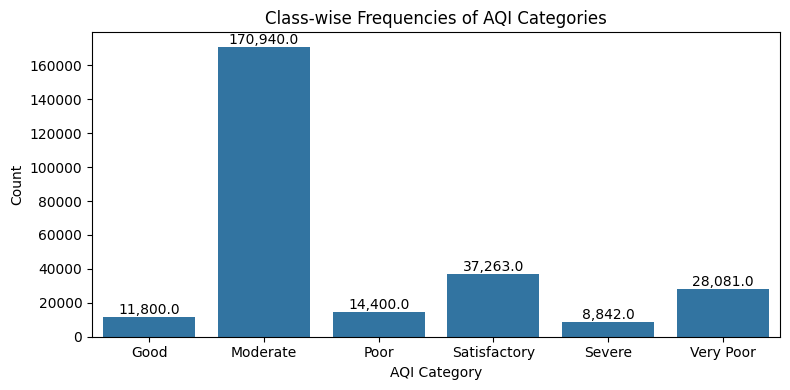

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,4))
sns.countplot(
    x='AQI_Category',
    data=df,
    order=freq_df.index  # ensures bars follow the same order as in freq_df
)
plt.title('Class-wise Frequencies of AQI Categories')
plt.xlabel('AQI Category')
plt.ylabel('Count')

# Annotate each bar with its height
for p in plt.gca().patches:
    plt.gca().annotate(
        f'{p.get_height():,}',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center', va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()


In [ ]:
le = LabelEncoder()

df['AQI_Enc'] = le.fit_transform(df[target])

X = df[features].values
y = df['AQI_Enc'].values


# ============================================================
# STEP 3: Stratified 80/20 Train-Test Split
# BEFORE Normalization
# ============================================================

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ============================================================
# STEP 4: Separate Validation Dataset
# 15% of the 80% training portion
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)


# ============================================================
# STEP 5: Normalize Features Without Data Leakage
# ============================================================

scaler = MinMaxScaler()

# Fit only on actual training data
X_train = scaler.fit_transform(X_train)

# Transform validation data
X_val = scaler.transform(X_val)

# Transform testing data
X_test = scaler.transform(X_test)


# ============================================================
# STEP 6: Confirm Class-Wise Distribution
# ============================================================

orig_counts = pd.Series(
    le.inverse_transform(y)
).value_counts().sort_index()

train_counts = pd.Series(
    le.inverse_transform(y_train)
).value_counts().sort_index()

val_counts = pd.Series(
    le.inverse_transform(y_val)
).value_counts().sort_index()

test_counts = pd.Series(
    le.inverse_transform(y_test)
).value_counts().sort_index()

split_df = pd.DataFrame({
    'Total': orig_counts,
    'Train': train_counts,
    'Validation': val_counts,
    'Test': test_counts
}).fillna(0).astype(int)

split_df['Train %'] = (
    split_df['Train'] / split_df['Total'] * 100
).round(2)

split_df['Validation %'] = (
    split_df['Validation'] / split_df['Total'] * 100
).round(2)

split_df['Test %'] = (
    split_df['Test'] / split_df['Total'] * 100
).round(2)

print("\n=== Class-Wise Dataset Distribution ===")
print(split_df)

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)


=== Class-Wise Dataset Distribution ===
               Total   Train  Validation   Test  Train %  Validation %  Test %
Good           11800    8024        1416   2360     68.0          12.0    20.0
Moderate      170940  116238       20513  34189     68.0          12.0    20.0
Poor           14400    9792        1728   2880     68.0          12.0    20.0
Satisfactory   37263   25339        4471   7453     68.0          12.0    20.0
Severe          8842    6013        1061   1768     68.0          12.0    20.0
Very Poor      28081   19095        3370   5616     68.0          12.0    20.0

Training shape: (184501, 6)
Validation shape: (32559, 6)
Testing shape: (54266, 6)


In [ ]:
import time
from tensorflow.keras import regularizers, callbacks

num_classes = len(le.classes_)

y_train_cat = utils.to_categorical(y_train, num_classes)
y_val_cat = utils.to_categorical(y_val, num_classes)
y_test_cat = utils.to_categorical(y_test, num_classes)

# ============================================================
# STEP 7: Reshape Features for CNN
# ============================================================

X_train_cnn = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_val_cnn = X_val.reshape(
    X_val.shape[0], X_val.shape[1], 1
)

X_test_cnn = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

print("CNN Training Shape:", X_train_cnn.shape)
print("CNN Validation Shape:", X_val_cnn.shape)
print("CNN Testing Shape:", X_test_cnn.shape)


# ============================================================
# STEP 8: Squeeze-and-Excitation (SE) Block
# ============================================================

def se_block(x, ratio=8):

    filters = int(x.shape[-1])

    se = layers.GlobalAveragePooling1D()(x)

    se = layers.Dense(
        max(filters // ratio, 1),
        activation='relu'
    )(se)

    se = layers.Dense(
        filters,
        activation='sigmoid'
    )(se)

    se = layers.Reshape((1, filters))(se)

    return layers.Multiply()([x, se])


# ============================================================
# STEP 9: Residual CNN Block
# ============================================================

def residual_block(x, filters, kernel_size=2, stride=1):

    res = x

    x = layers.Conv1D(
        filters,
        kernel_size,
        strides=stride,
        padding='same'
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv1D(
        filters,
        kernel_size,
        padding='same'
    )(x)

    # FIXED: Pass x positionally instead of using 'res = x' keyword syntax
    x = layers.BatchNormalization()(x)

    if res.shape[-1] != filters or stride != 1:

        res = layers.Conv1D(
            filters,
            1,
            strides=stride,
            padding='same'
        )(res)

        res = layers.BatchNormalization()(res)

    x = layers.Add()([x, res])
    x = layers.Activation('relu')(x)

    x = se_block(x)

    return x


# ============================================================
# STEP 10: Build Residual CNN + SE Attention
# Original Architecture Preserved
# ============================================================

inputs = tf.keras.Input(shape=(len(features), 1))

# Initial Convolution
x = layers.Conv1D(
    64,
    kernel_size=2,
    padding='same',
    activation='relu'
)(inputs)

x = layers.BatchNormalization()(x)

# Residual Stacks
x = residual_block(x, 64, kernel_size=2)

x = residual_block(
    x, 128, kernel_size=2, stride=1
)

x = residual_block(
    x, 256, kernel_size=2, stride=1
)

# Global Average Pooling
x = layers.GlobalAveragePooling1D()(x)

# Dense Layer 1
x = layers.Dense(
    128,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

# Dense Layer 2
x = layers.Dense(
    64,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.3)(x)

# Output Layer
outputs = layers.Dense(
    num_classes,
    activation='softmax'
)(x)

model = models.Model(inputs, outputs)


# ============================================================
# STEP 11: Compile CNN Model
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================================
# STEP 12: Callbacks
# ============================================================

es = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

rlr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3
)


# ============================================================
# STEP 13: Train CNN Model
# Use Separate Validation Dataset
# ============================================================

start_time = time.perf_counter()

history = model.fit(
    X_train_cnn,
    y_train_cat,

    validation_data=(
        X_val_cnn,
        y_val_cat
    ),

    epochs=50,
    batch_size=32,
    verbose=2,
    callbacks=[es, rlr]
)

training_time = time.perf_counter() - start_time

print(f"\nTraining Time: {training_time:.2f} seconds")


# ============================================================
# STEP 14: Final Model Evaluation
# ============================================================

train_loss, train_acc = model.evaluate(
    X_train_cnn, y_train_cat, verbose=0
)

val_loss, val_acc = model.evaluate(
    X_val_cnn, y_val_cat, verbose=0
)

test_loss, test_acc = model.evaluate(
    X_test_cnn, y_test_cat, verbose=0
)

print("\n=== CNN Accuracy ===")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

CNN Training Shape: (184501, 6, 1)
CNN Validation Shape: (32559, 6, 1)
CNN Testing Shape: (54266, 6, 1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 6, 64)     │        192 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 6, 64)     │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 6, 64)     │      8,256 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 64)     │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 6, 64)     │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 6, 64)     │      8,256 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 64)     │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 6, 64)     │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 6, 64)     │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ activation_1[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │        520 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        576 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 64)     │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 6, 64)     │          0 │ activation_1[0][… │
│                     │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 6, 128)    │     16,512 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 128)    │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 6, 128)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 6, 128)    │     32,896 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 374,270 (1.43 MB)

 Trainable params: 371,198 (1.42 MB)

 Non-trainable params: 3,072 (12.00 KB)

Epoch 1/50
5766/5766 - 89s - 15ms/step - accuracy: 0.9248 - loss: 0.2303 - val_accuracy: 0.9631 - val_loss: 0.1093 - learning_rate: 0.0010
Epoch 2/50
5766/5766 - 79s - 14ms/step - accuracy: 0.9606 - loss: 0.1183 - val_accuracy: 0.9564 - val_loss: 0.1233 - learning_rate: 0.0010
Epoch 3/50
5766/5766 - 79s - 14ms/step - accuracy: 0.9675 - loss: 0.0949 - val_accuracy: 0.9641 - val_loss: 0.1033 - learning_rate: 0.0010
Epoch 4/50
5766/5766 - 78s - 14ms/step - accuracy: 0.9719 - loss: 0.0800 - val_accuracy: 0.9606 - val_loss: 0.1090 - learning_rate: 0.0010
Epoch 5/50
5766/5766 - 78s - 14ms/step - accuracy: 0.9749 - loss: 0.0720 - val_accuracy: 0.9508 - val_loss: 0.1325 - learning_rate: 0.0010
Epoch 6/50
5766/5766 - 78s - 13ms/step - accuracy: 0.9769 - loss: 0.0665 - val_accuracy: 0.9803 - val_loss: 0.0541 - learning_rate: 0.0010
Epoch 7/50
5766/5766 - 77s - 13ms/step - accuracy: 0.9773 - loss: 0.0640 - val_accuracy: 0.9672 - val_loss: 0.1013 - learning_rate: 0.0010
Epoch 8/50
5766/5766 - 77s 


=== CNN Performance Summary ===
 Model Dataset  Train Accuracy  Validation Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1  Macro AP  Training Time (s)  Inference Time (s)
CNN-SE   Merge          0.9984               0.9967         0.9964           0.9932        0.9932    0.9932              0.9964           0.9964       0.9964    0.9997          2904.0322              8.9434

=== CNN Classification Report ===
              precision    recall  f1-score   support

        Good     0.9844    0.9907    0.9875      2360
    Moderate     0.9985    0.9989    0.9987     34189
        Poor     0.9868    0.9896    0.9882      2880
Satisfactory     0.9935    0.9915    0.9925      7453
      Severe     0.9983    0.9938    0.9960      1768
   Very Poor     0.9973    0.9950    0.9962      5616

    accuracy                         0.9964     54266
   macro avg     0.9932    0.9932    0.9932     54266
weighted avg     0.9964    0.9

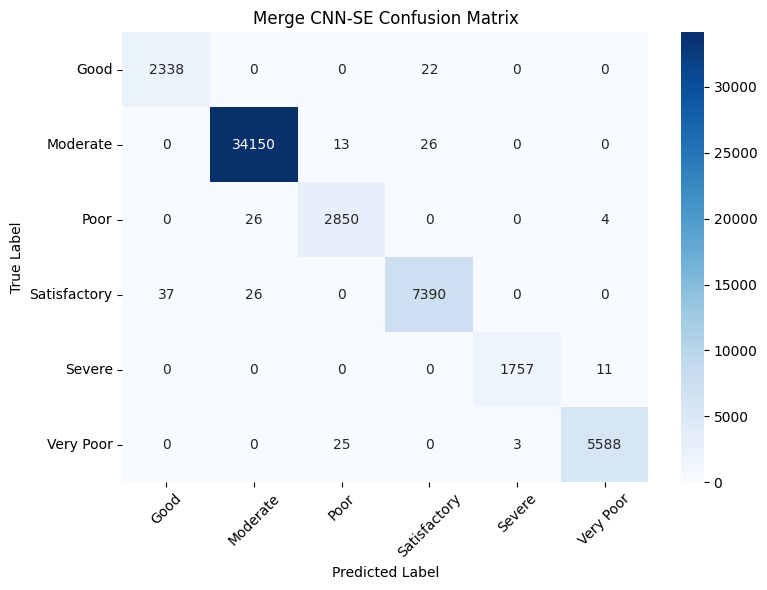

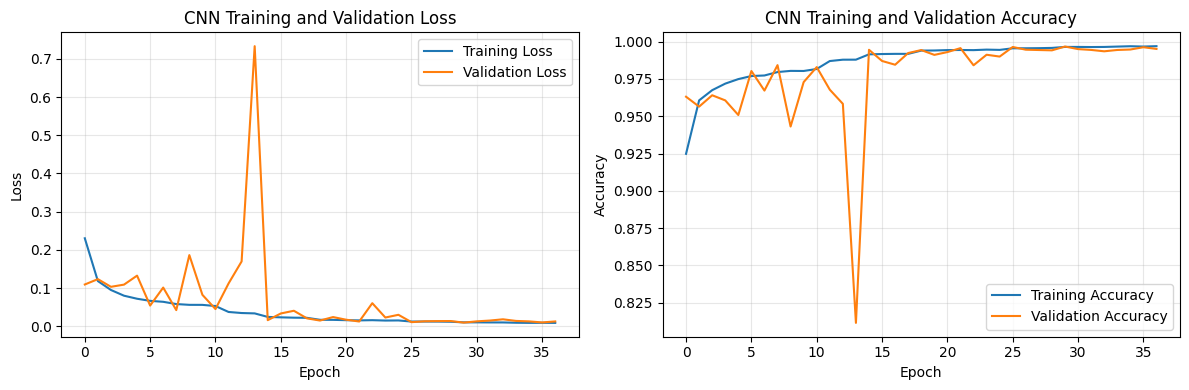


=== CNN-SE OVERALL AP ===
Macro AP    : 0.999684
Weighted AP : 0.999823
Micro AP    : 0.999862

=== CNN-SE CLASS-WISE AP ===
 Model Dataset AQI Category  Support  Average Precision
CNN-SE   Merge         Good     2360           0.999533
CNN-SE   Merge     Moderate    34189           0.999895
CNN-SE   Merge         Poor     2880           0.999019
CNN-SE   Merge Satisfactory     7453           0.999783
CNN-SE   Merge       Severe     1768           0.999935
CNN-SE   Merge    Very Poor     5616           0.999937

=== UPDATED CNN-SE PERFORMANCE SUMMARY ===
 Model Dataset  Train Accuracy  Validation Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1  Macro AP  Training Time (s)  Inference Time (s)  Weighted AP  Micro AP
CNN-SE   Merge        0.998444             0.996714       0.996443         0.993151      0.993243  0.993194            0.996447         0.996443     0.996444  0.999684        2904.032212            8.943426  

In [ ]:
# ============================================================
# INITIALIZATION & GLOBAL PATHS
# ============================================================

from pathlib import Path

SAVE_DIR = Path(
    "/content/drive/MyDrive/My work/"
    "Air Quality Project/Paper 1(External Data)/New/"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# STEP 17: Predictions and Inference Time
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

start_time = time.perf_counter()

y_pred_prob = model.predict(
    X_test_cnn,
    verbose=0
)

inference_time = time.perf_counter() - start_time

y_pred = np.argmax(y_pred_prob, axis=1)


# ============================================================
# STEP 18: Performance Metrics
# ============================================================

acc = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

weighted_precision = precision_score(
    y_test, y_pred,
    average='weighted',
    zero_division=0
)

weighted_recall = recall_score(
    y_test, y_pred,
    average='weighted',
    zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred,
    average='weighted',
    zero_division=0
)

macro_ap = average_precision_score(
    y_test_cat,
    y_pred_prob,
    average='macro'
)


# ============================================================
# STEP 19: Results Summary
# ============================================================

results_df = pd.DataFrame([{
    'Model': 'CNN-SE',
    'Dataset': 'Merge',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Test Accuracy': acc,
    'Macro Precision': macro_precision,
    'Macro Recall': macro_recall,
    'Macro F1': macro_f1,
    'Weighted Precision': weighted_precision,
    'Weighted Recall': weighted_recall,
    'Weighted F1': weighted_f1,
    'Macro AP': macro_ap,
    'Training Time (s)': training_time,
    'Inference Time (s)': inference_time
}])

print("\n=== CNN Performance Summary ===")

print(results_df.round(4).to_string(index=False))


# ============================================================
# STEP 20: Classification Report
# ============================================================

class_names = [str(c) for c in le.classes_]
class_labels = np.arange(num_classes)

print("\n=== CNN Classification Report ===")

print(
    classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# STEP 21: Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Merge CNN-SE Confusion Matrix')

plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    SAVE_DIR / "CNN_SE_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# STEP 22: Training Curves
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4)
)

# Loss Curves
ax1.plot(
    history.history['loss'],
    label='Training Loss'
)

ax1.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

ax1.set_title('CNN Training and Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Accuracy Curves
ax2.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

ax2.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

ax2.set_title('CNN Training and Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    SAVE_DIR / "CNN_SE_Training_Curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# STEP 23: COMPLETE AP EVALUATION AND SAVE CNN-SE RESULTS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    classification_report
)

# ============================================================
# 23.2 PREPARE CLASS LABELS AND PROBABILITIES
# ============================================================

y_true_onehot = np.asarray(y_test_cat)
y_prob = np.asarray(y_pred_prob)

y_true = np.asarray(y_test).reshape(-1)

class_names = [str(c) for c in le.classes_]
class_labels = np.arange(len(class_names))

# Validate shapes and label alignment
assert y_true_onehot.shape == y_prob.shape, (
    "One-hot labels and predicted probabilities "
    "must have the same shape."
)

assert y_prob.shape[1] == len(class_names), (
    "Class count does not match model outputs."
)

assert np.array_equal(
    np.argmax(y_true_onehot, axis=1),
    y_true
), "One-hot labels do not match y_test."

# Confirm every category appears in the test set
assert np.all(y_true_onehot.sum(axis=0) > 0), (
    "At least one AQI category has no positive "
    "samples in the test set."
)

# ============================================================
# 23.3 CALCULATE OVERALL AP
# ============================================================

macro_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="macro"
)

weighted_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="weighted"
)

micro_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="micro"
)

print("\n=== CNN-SE OVERALL AP ===")

print(f"Macro AP    : {macro_ap:.6f}")
print(f"Weighted AP : {weighted_ap:.6f}")
print(f"Micro AP    : {micro_ap:.6f}")

# ============================================================
# 23.4 CLASS-WISE AP FOR ALL SIX AQI CATEGORIES
# ============================================================

classwise_ap_results = []

for i, class_name in enumerate(class_names):

    class_ap = average_precision_score(
        y_true_onehot[:, i],
        y_prob[:, i]
    )

    classwise_ap_results.append({
        "Model": "CNN-SE",
        "Dataset": "Merge",
        "AQI Category": class_name,
        "Support": int(y_true_onehot[:, i].sum()),
        "Average Precision": class_ap
    })

cnn_classwise_ap_df = pd.DataFrame(
    classwise_ap_results
)

print("\n=== CNN-SE CLASS-WISE AP ===")

print(
    cnn_classwise_ap_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 23.5 UPDATE EXISTING RESULTS SUMMARY
# ============================================================

results_df["Macro AP"] = macro_ap
results_df["Weighted AP"] = weighted_ap
results_df["Micro AP"] = micro_ap

print("\n=== UPDATED CNN-SE PERFORMANCE SUMMARY ===")

print(
    results_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 23.6 GENERATE CLASSIFICATION REPORT
# ============================================================

report_dict = classification_report(
    y_true,
    y_pred,
    labels=class_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T

# ============================================================
# 23.7 SAVE ALL CNN-SE RESULTS TO GOOGLE DRIVE
# ============================================================

# Overall performance metrics
results_df.to_csv(
    SAVE_DIR / "CNN_SE_Overall_Results_AP.csv",
    index=False
)

# Six class-wise AP scores
cnn_classwise_ap_df.to_csv(
    SAVE_DIR / "CNN_SE_Classwise_AP.csv",
    index=False
)

# Classification report
report_df.to_csv(
    SAVE_DIR / "CNN_SE_Classification_Report.csv"
)

# Confusion matrix values
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    SAVE_DIR / "CNN_SE_Confusion_Matrix.csv"
)

# ============================================================
# 23.8 CONFIRM SAVED FILES
# ============================================================

print("\n=== CNN-SE RESULTS SAVED ===")

print("Directory:", SAVE_DIR)

for filename in [
    "CNN_SE_Overall_Results_AP.csv",
    "CNN_SE_Classwise_AP.csv",
    "CNN_SE_Classification_Report.csv",
    "CNN_SE_Confusion_Matrix.csv"
]:
    print("Saved:", SAVE_DIR / filename)


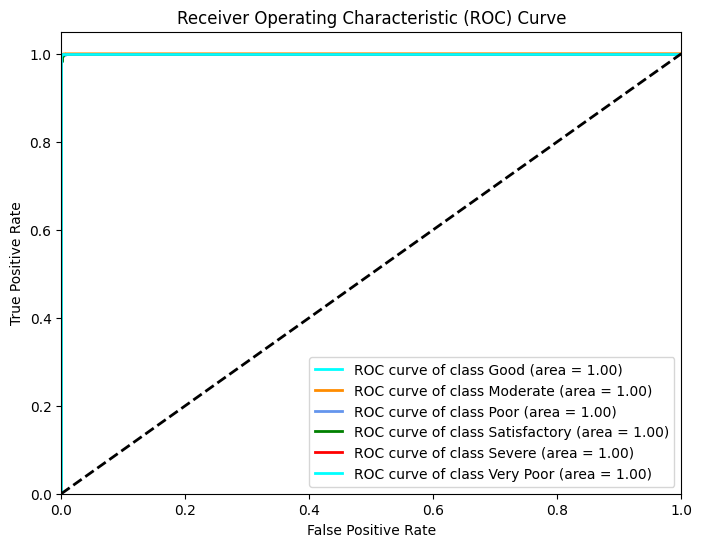

In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_cat[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(le.classes_[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

1696/1696 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step


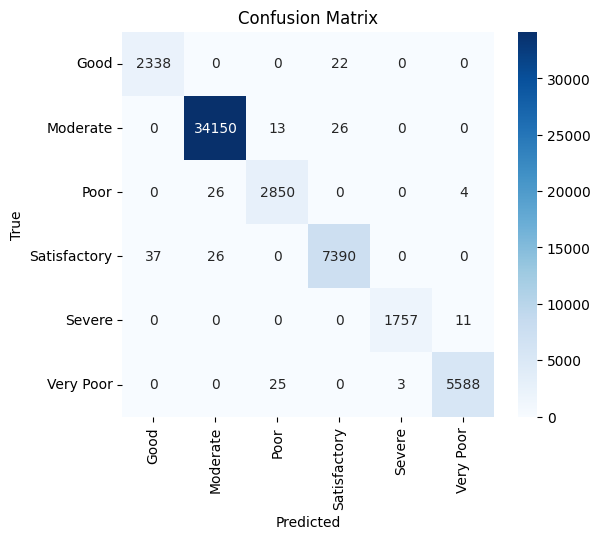

In [ ]:
y_pred_prob = model.predict(X_test_cnn)
y_pred      = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=le.classes_, yticklabels=le.classes_,
            cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

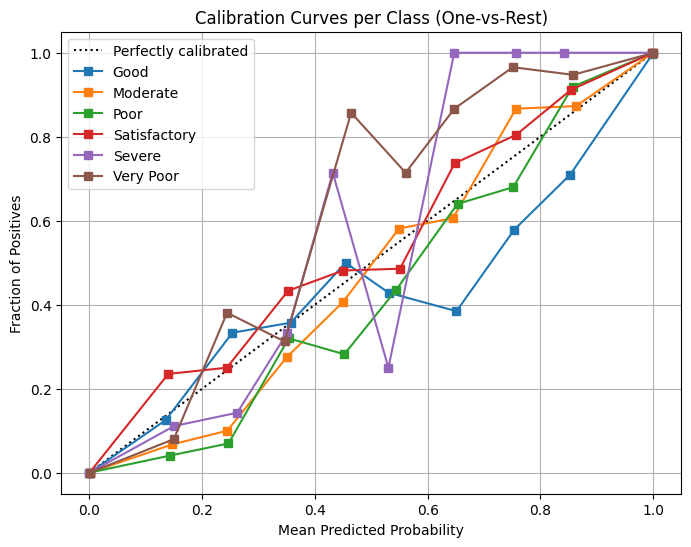

In [ ]:
from sklearn.calibration import CalibrationDisplay

# Assuming y_test_bin and y_pred_probs are already available from previous cells
# y_test_bin: binarized true labels (one-hot encoded)
# y_pred_probs: predicted probabilities from model.predict()

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(le.classes_):
    CalibrationDisplay.from_predictions(
        y_test_cat[:, i],
        y_pred_prob[:, i],
        n_bins=10,
        name=f'{class_name}',
        ax=plt.gca() # Plot all curves on the same axes
    )

plt.title('Calibration Curves per Class (One-vs-Rest)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

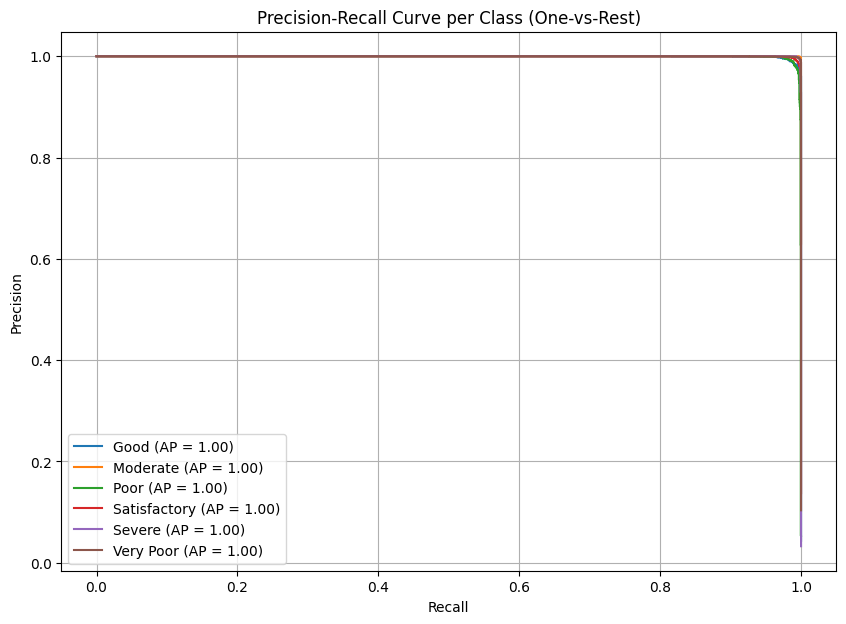

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(le.classes_):
    precision, recall, _ = precision_recall_curve(y_test_cat[:, i], y_pred_prob[:, i])
    ap_score = average_precision_score(y_test_cat[:, i], y_pred_prob[:, i])
    plt.plot(recall, precision, label=f'{class_name} (AP = {ap_score:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve per Class (One-vs-Rest)')
plt.legend()
plt.grid(True)
plt.show()